In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Entorno:", sys.executable)
print("Pandas:", pd.__version__)

Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Entorno: c:\Users\horac\TC5061-Proyecto-Equipo16\.venv\Scripts\python.exe
Pandas: 3.0.6


# Análisis exploratorio de viajes MiBici

**Proyecto:** TC5061 - Equipo 16  
**Responsable:** HH2  
**Periodo de estudio:** Octubre 2024 – Septiembre 2026

## Objetivo

Explorar la calidad, distribución y comportamiento temporal de
los viajes del sistema MiBici para diseñar las variables de tres
problemas de Machine Learning:

- P1: Predicción de demanda diaria por estación (regresión).
- P2: Clasificación del riesgo de desequilibrio por franjas de 3 horas.
- P3: Agrupamiento de estaciones según sus perfiles horarios.

## Metodología

1. Validación del esquema y calidad de los datos.
2. Análisis de viajes y estaciones.
3. Exploración de la demanda diaria.
4. Análisis del flujo neto y umbrales de riesgo.
5. Exploración de perfiles horarios.
6. Definición de reglas de limpieza y feature engineering.

In [2]:
#Datos sínteticos de viajes y estaciones
viajes = pd.DataFrame({
    "viaje_id": [1, 2, 3, 4, 5, 6],
    "inicio": pd.to_datetime([
        "2026-03-01 08:00",
        "2026-03-01 08:30",
        "2026-03-01 09:00",
        "2026-03-02 17:00",
        "2026-03-02 18:00",
        "2026-03-03 07:30",
    ]),
    "fin": pd.to_datetime([
        "2026-03-01 08:15",
        "2026-03-01 08:50",
        "2026-03-01 09:20",
        "2026-03-02 17:15",
        "2026-03-02 18:20",
        "2026-03-03 07:45",
    ]),
    "origen_id": [1, 1, 2, 1, 2, 1],
    "destino_id": [2, 2, 1, 2, 1, 2],
})

estaciones = pd.DataFrame({
    "estacion_id": [1, 2, 3],
    "nombre": ["GDL Centro", "ZPN Norte", "GDL Sur"],
    "municipio": ["GDL", "ZPN", "GDL"],
    "latitud": [20.67, 20.70, 20.65],
    "longitud": [-103.35, -103.40, -103.33],
    "capacidad": [20, 15, 10],
    "activa": [True, True, True],
})

display(viajes)
display(estaciones)

,viaje_id,inicio,fin,origen_id,destino_id
0,1,2026-03-01 08:00:00,2026-03-01 08:15:00,1,2
1,2,2026-03-01 08:30:00,2026-03-01 08:50:00,1,2
2,3,2026-03-01 09:00:00,2026-03-01 09:20:00,2,1
3,4,2026-03-02 17:00:00,2026-03-02 17:15:00,1,2
4,5,2026-03-02 18:00:00,2026-03-02 18:20:00,2,1
5,6,2026-03-03 07:30:00,2026-03-03 07:45:00,1,2


,estacion_id,nombre,municipio,latitud,longitud,capacidad,activa
0,1,GDL Centro,GDL,20.67,-103.35,20,True
1,2,ZPN Norte,ZPN,20.70,-103.40,15,True
2,3,GDL Sur,GDL,20.65,-103.33,10,True


In [3]:
print("Total de viajes:", len(viajes))
print("Total de estaciones:", len(estaciones))

print("\nTipos de datos:")
print(viajes.dtypes)

print("\nValores faltantes:")
print(viajes.isna().sum())

print("\nViajes duplicados:")
print(viajes["viaje_id"].duplicated().sum())

viajes["duracion_min"] = (
    viajes["fin"] - viajes["inicio"]
).dt.total_seconds() / 60

print("\nEstadísticas de duración:")
display(viajes["duracion_min"].describe())

Total de viajes: 6
Total de estaciones: 3

Tipos de datos:
viaje_id               int64
inicio        datetime64[us]
fin           datetime64[us]
origen_id              int64
destino_id             int64
dtype: object

Valores faltantes:
viaje_id      0
inicio        0
fin           0
origen_id     0
destino_id    0
dtype: int64

Viajes duplicados:
0

Estadísticas de duración:


count     6.000000
mean     17.500000
std       2.738613
min      15.000000
25%      15.000000
50%      17.500000
75%      20.000000
max      20.000000
Name: duracion_min, dtype: float64

In [4]:
# ---- P1: Demanda diaria por estación ---- #

df_demanda = viajes.copy()

# Extraer fecha de inicio del viaje
df_demanda["fecha"] = df_demanda["inicio"].dt.normalize()

# Contar salidas por estación y día
df_demanda = (
    df_demanda
    .groupby(["origen_id", "fecha"])
    .size()
    .reset_index(name="demanda")
    .rename(columns={"origen_id": "estacion_id"})
)

display(df_demanda)

,estacion_id,fecha,demanda
0,1,2026-03-01,2
1,1,2026-03-02,1
2,1,2026-03-03,1
3,2,2026-03-01,1
4,2,2026-03-02,1


In [5]:
# ---- Crear calendario completo por estación ---- #

fechas = pd.date_range(
    start=viajes["inicio"].min().normalize(),
    end=viajes["inicio"].max().normalize(),
    freq="D"
)

# Todas las combinaciones estación-fecha
indice_completo = pd.MultiIndex.from_product(
    [
        estaciones["estacion_id"],
        fechas
    ],
    names=["estacion_id", "fecha"]
)

# Completar los días sin viajes con cero
df_demanda_completa = (
    df_demanda
    .set_index(["estacion_id", "fecha"])
    .reindex(indice_completo, fill_value=0)
    .reset_index()
    .sort_values(["estacion_id", "fecha"])
    .reset_index(drop=True)
)

display(df_demanda_completa)

,estacion_id,fecha,demanda
0,1,2026-03-01,2
1,1,2026-03-02,1
2,1,2026-03-03,1
3,2,2026-03-01,1
4,2,2026-03-02,1
5,2,2026-03-03,0
6,3,2026-03-01,0
7,3,2026-03-02,0
8,3,2026-03-03,0


In [6]:
# ---- Validaciones de P1 ---- #

# Se conservan las seis salidas originales
assert df_demanda_completa["demanda"].sum() == len(viajes)

# Tres estaciones durante tres días
assert len(df_demanda_completa) == 9

# La estación 3 no tiene salidas
assert (
    df_demanda_completa
    .query("estacion_id == 3")["demanda"]
    .eq(0)
    .all()
)

# No existen combinaciones duplicadas
assert not df_demanda_completa.duplicated(
    subset=["estacion_id", "fecha"]
).any()

print("Todas las validaciones de P1 fueron exitosas.")

Todas las validaciones de P1 fueron exitosas.


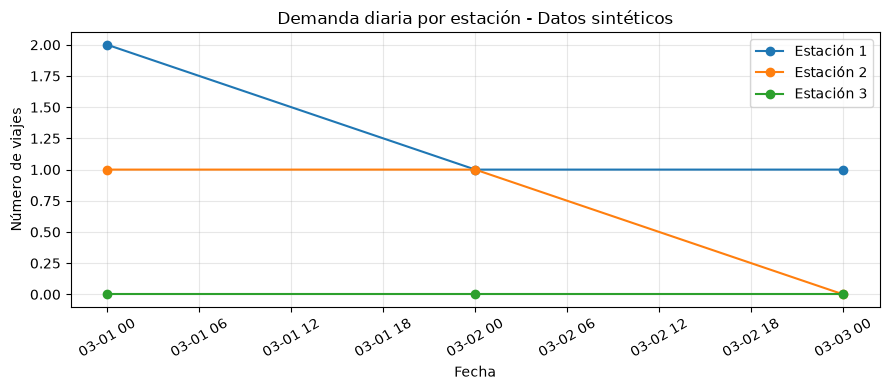

In [7]:
# ---- Visualización de demanda diaria ---- #

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

for estacion_id, grupo in df_demanda_completa.groupby("estacion_id"):
    ax.plot(
        grupo["fecha"],
        grupo["demanda"],
        marker="o",
        label=f"Estación {estacion_id}"
    )

ax.set(
    title="Demanda diaria por estación - Datos sintéticos",
    xlabel="Fecha",
    ylabel="Número de viajes"
)

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()